(50000, 28)


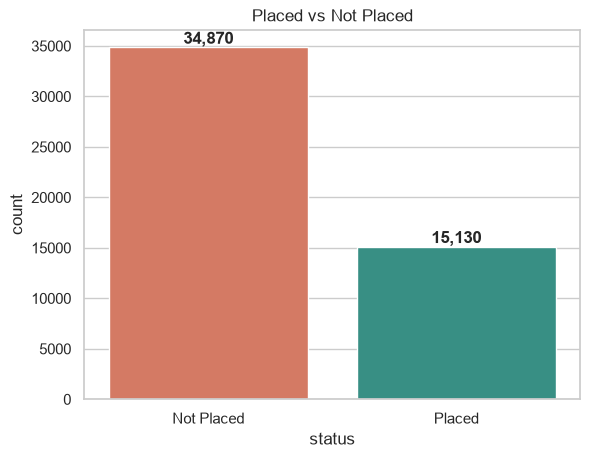

Overall placement rate: 30.26 %


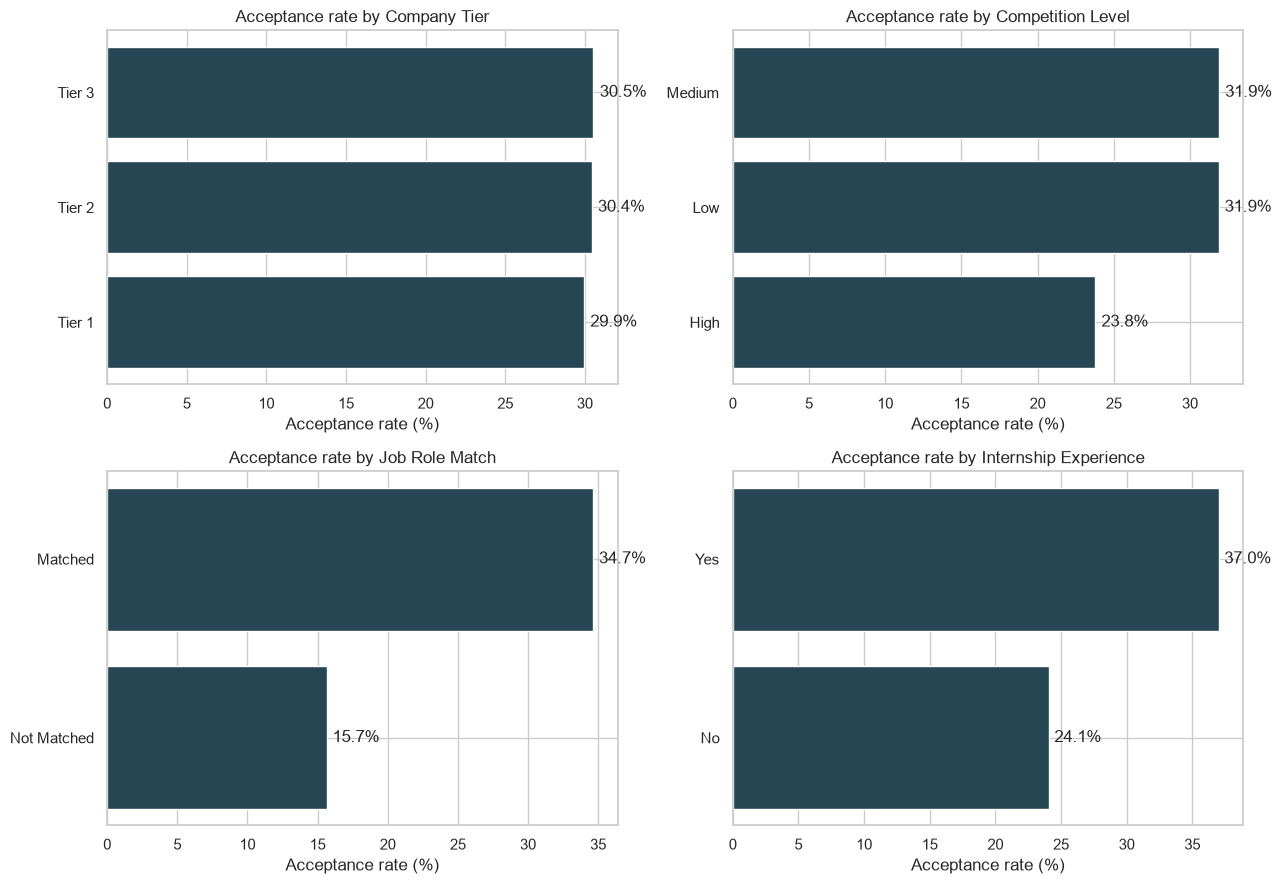

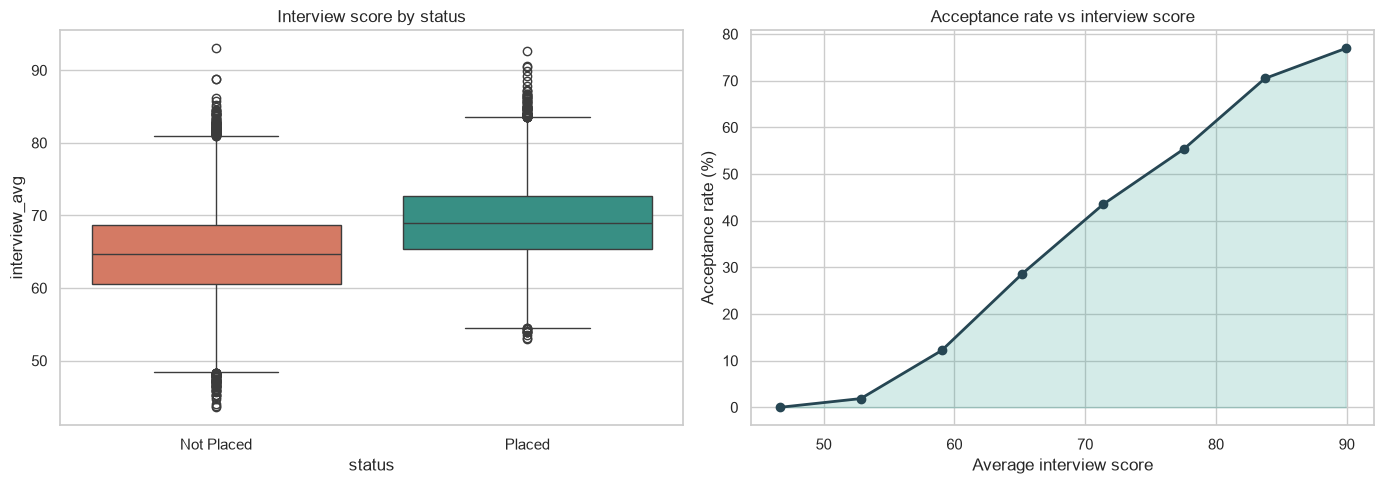

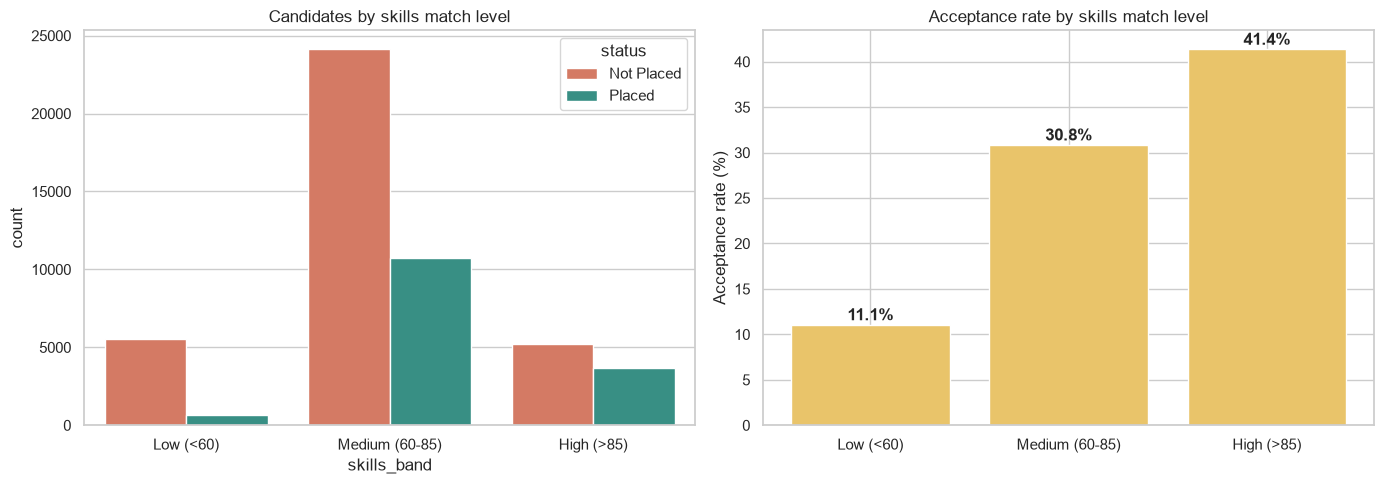

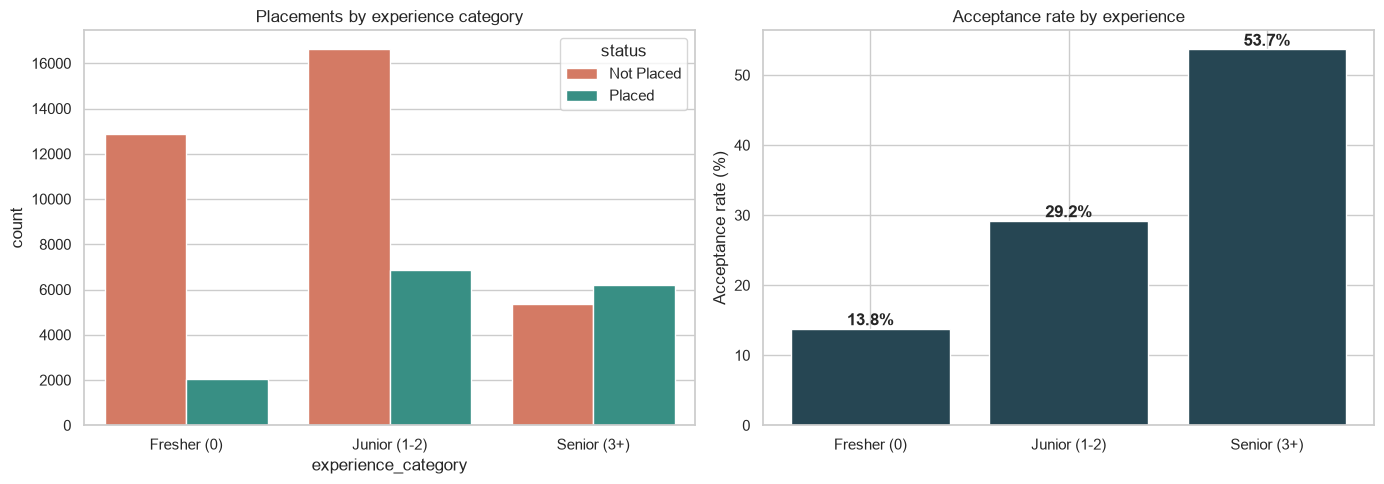

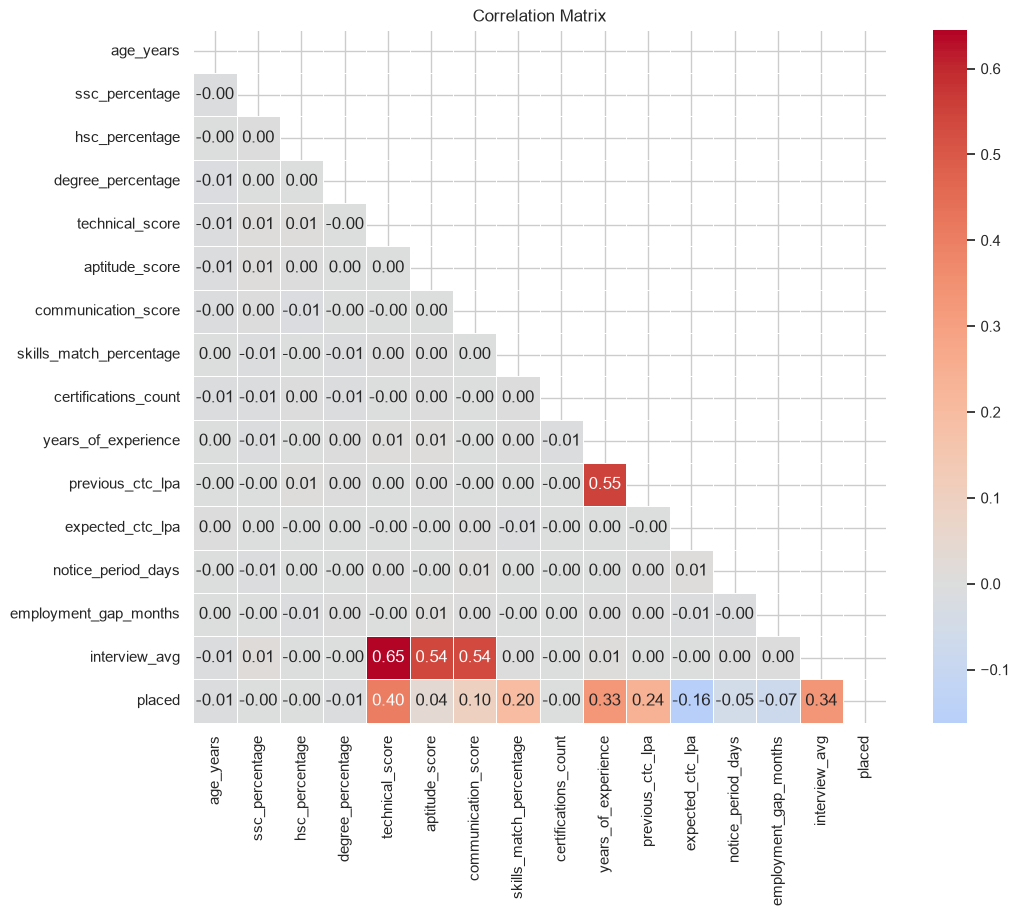

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

%matplotlib inline
sns.set_theme(style="whitegrid", palette="viridis")
df = pd.read_csv("Cleaned_Dataset.csv")
df["interview_avg"] = df[["technical_score", "aptitude_score", "communication_score"]].mean(axis=1)
df["placed"] = (df["status"] == "Placed").astype(int)
os.makedirs("figures", exist_ok=True)
print(df.shape)

ax = sns.countplot(data=df, x="status", hue="status", legend=False,
                   palette={"Placed": "#2a9d8f", "Not Placed": "#e76f51"})
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontweight="bold")
plt.title("Placed vs Not Placed")
plt.savefig("figures/1_target_distribution.png", bbox_inches="tight")
plt.show()
print("Overall placement rate:", round(df["placed"].mean() * 100, 2), "%")

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
combos = [("company_tier", "Company Tier"), ("competition_level", "Competition Level"),
          ("job_role_match", "Job Role Match"), ("internship_experience", "Internship Experience")]
for ax, (col, title) in zip(axes.flat, combos):
    rate = df.groupby(col)["placed"].mean().mul(100).sort_values()
    bars = ax.barh(rate.index, rate.values, color="#264653")
    for b, v in zip(bars, rate.values):
        ax.text(v + 0.4, b.get_y() + b.get_height()/2, f"{v:.1f}%", va="center")
    ax.set_title(f"Acceptance rate by {title}")
    ax.set_xlabel("Acceptance rate (%)")
plt.tight_layout()
plt.savefig("figures/2_acceptance_by_category.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x="status", y="interview_avg", hue="status", legend=False, ax=axes[0],
            palette={"Placed": "#2a9d8f", "Not Placed": "#e76f51"})
axes[0].set_title("Interview score by status")

df["interview_band"] = pd.cut(df["interview_avg"], bins=8)
rate = df.groupby("interview_band", observed=True)["placed"].mean().mul(100)
mid = [(i.left + i.right)/2 for i in rate.index]
axes[1].plot(mid, rate.values, marker="o", color="#264653", linewidth=2)
axes[1].fill_between(mid, rate.values, alpha=0.2, color="#2a9d8f")
axes[1].set_title("Acceptance rate vs interview score")
axes[1].set_xlabel("Average interview score")
axes[1].set_ylabel("Acceptance rate (%)")

plt.tight_layout()
plt.savefig("figures/3_interview_vs_acceptance.png", bbox_inches="tight")
plt.show()

df["skills_band"] = pd.cut(df["skills_match_percentage"],
                           bins=[0, 60, 85, 100],
                           labels=["Low (<60)", "Medium (60-85)", "High (>85)"])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x="skills_band", hue="status", ax=axes[0],
              palette={"Placed": "#2a9d8f", "Not Placed": "#e76f51"})
axes[0].set_title("Candidates by skills match level")

rate = df.groupby("skills_band", observed=True)["placed"].mean().mul(100)
bars = axes[1].bar(rate.index.astype(str), rate.values, color="#e9c46a")
for b, v in zip(bars, rate.values):
    axes[1].text(b.get_x() + b.get_width()/2, v + 0.5, f"{v:.1f}%", ha="center", fontweight="bold")
axes[1].set_title("Acceptance rate by skills match level")
axes[1].set_ylabel("Acceptance rate (%)")

plt.tight_layout()
plt.savefig("figures/4_skills_match_impact.png", bbox_inches="tight")
plt.show()

df["experience_category"] = pd.cut(df["years_of_experience"],
                                   bins=[-1, 0, 2, 10],
                                   labels=["Fresher (0)", "Junior (1-2)", "Senior (3+)"])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x="experience_category", hue="status", ax=axes[0],
              palette={"Placed": "#2a9d8f", "Not Placed": "#e76f51"})
axes[0].set_title("Placements by experience category")

rate = df.groupby("experience_category", observed=True)["placed"].mean().mul(100)
bars = axes[1].bar(rate.index.astype(str), rate.values, color="#264653")
for b, v in zip(bars, rate.values):
    axes[1].text(b.get_x() + b.get_width()/2, v + 0.5, f"{v:.1f}%", ha="center", fontweight="bold")
axes[1].set_title("Acceptance rate by experience")
axes[1].set_ylabel("Acceptance rate (%)")

plt.tight_layout()
plt.savefig("figures/5_experience_vs_placement.png", bbox_inches="tight")
plt.show()

corr = df.select_dtypes(include="number").corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(12, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True, linewidths=0.5)
plt.title("Correlation Matrix")
plt.savefig("figures/6_correlation_heatmap.png", bbox_inches="tight")
plt.show()